# Citation Graph Analyser

Steps: 
**1** Data Preparation
**2** Graph Construction
**3** Graph Analysis (citation count, PageRank, connected components) 
**4** Comparative Evaluation
**5** Presentation(Neo4j)

## Setup

In [1]:
import sys, os

project_root = os.getcwd()
sys.path.append(project_root)
print("Project root:", project_root)

Project root: /Users/thilini/Documents/MSc/Data_intensive_computing/Assignments/Project/code/graph_analyser


In [2]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from config import config

PACKAGES = (
    "graphframes:graphframes:0.8.3-spark3.5-s_2.12,"
    "org.neo4j:neo4j-connector-apache-spark_2.12:5.3.1_for_spark_3"
)

spark = (
    SparkSession.builder
    .appName(config.SPARK_APP_NAME)
    .master(config.SPARK_MASTER)
    .config("spark.jars.packages", PACKAGES)
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
spark

26/10/04 18:06:50 WARN Utils: Your hostname, Thilinis-MacBook-Pro.local resolves to a loopback address: 127.0.0.1; using 192.168.1.8 instead (on interface en0)
26/10/04 18:06:50 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Ivy Default Cache set to: /Users/thilini/.ivy2/cache
The jars for the packages stored in: /Users/thilini/.ivy2/jars
graphframes#graphframes added as a dependency
org.neo4j#neo4j-connector-apache-spark_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-0e423010-724e-4ef0-904d-310ac871c69b;1.0
	confs: [default]
	found graphframes#graphframes;0.8.3-spark3.5-s_2.12 in spark-packages
	found org.slf4j#slf4j-api;1.7.16 in central
	found org.neo4j#neo4j-connector-apache-spark_2.12;5.3.1_for_spark_3 in central
	found org.neo4j#neo4j-connector-apache-spark_2.12_common;5.3.1 in central


:: loading settings :: url = jar:file:/Users/thilini/.pyenv/versions/3.12.0/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


	found org.neo4j.driver#neo4j-java-driver;4.4.17 in central
	found org.reactivestreams#reactive-streams;1.0.4 in central
	found org.apache.xbean#xbean-asm6-shaded;4.10 in central
	found org.neo4j#neo4j-cypher-dsl;2022.9.2 in central
	found org.apiguardian#apiguardian-api;1.1.2 in local-m2-cache
:: resolution report :: resolve 103ms :: artifacts dl 4ms
	:: modules in use:
	graphframes#graphframes;0.8.3-spark3.5-s_2.12 from spark-packages in [default]
	org.apache.xbean#xbean-asm6-shaded;4.10 from central in [default]
	org.apiguardian#apiguardian-api;1.1.2 from local-m2-cache in [default]
	org.neo4j#neo4j-connector-apache-spark_2.12;5.3.1_for_spark_3 from central in [default]
	org.neo4j#neo4j-connector-apache-spark_2.12_common;5.3.1 from central in [default]
	org.neo4j#neo4j-cypher-dsl;2022.9.2 from central in [default]
	org.neo4j.driver#neo4j-java-driver;4.4.17 from central in [default]
	org.reactivestreams#reactive-streams;1.0.4 from central in [default]
	org.slf4j#slf4j-api;1.7.16 from

## Phase 1 - Data Preparation
### 1.1 Ingestion (HDFS)

In [6]:
from src.ingestion.hdfs_loader import HDFSLoader

loader = HDFSLoader(spark)
loader.upload_to_hdfs()
raw_df = loader.read_raw_edges()
raw_df.show(5)


print(f"[BEFORE cleaning] raw edge rows: {raw_df.count()}")

2026-10-04 18:13:57,481 WARN util.NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
2026-10-04 18:13:58,004 WARN util.NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Files uploaded into HDFS: /Users/thilini/Documents/MSc/Data_intensive_computing/Assignments/Project/code/graph_analyser/dataset/cit-HepPh.txt -> hdfs://localhost:9000/data/citation/raw/cit-HepPh.txt
Read 421578 raw rows from hdfs://localhost:9000/data/citation/raw/cit-HepPh.txt
+-------+-------+
|from_id|  to_id|
+-------+-------+
|9907233|9301253|
|9907233|9504304|
|9907233|9505235|
|9907233|9506257|
|9907233|9606402|
+-------+-------+
only showing top 5 rows

[BEFORE cleaning] raw edge rows: 421578


### 1.2 Cleaning (Spark SQL)

In [12]:
from src.processing.data_cleaner import DataCleaner

cleaner = DataCleaner(spark)
cleaned_edges = cleaner.clean_edges(raw_df)
cleaned_edges.show(5)

vertices = cleaner.build_vertices(cleaned_edges)
edges = cleaner.build_edges(cleaned_edges)

vertices.show(5)

Cleaned edge count: 421534
+-------+-------+
|from_id|  to_id|
+-------+-------+
|9803214|9301253|
|9611297|9504304|
|9903217|9610282|
|9903217|9803242|
| 112133|   2171|
+-------+-------+
only showing top 5 rows

Vertex count: 34546
+-------+
|     id|
+-------+
|9611297|
|9403384|
|9903229|
| 211308|
|9801317|
+-------+
only showing top 5 rows



In [13]:
cleaner.persist_to_hdfs(vertices, edges)

 Wrote vertices -> hdfs://localhost:9000/data/citation/processed/vertices.parquet, edges -> hdfs://localhost:9000/data/citation/processed/edges.parquet


## Phase 2 - Graph Construction

In [14]:
from src.graph.graph_builder import GraphBuilder

graph = GraphBuilder.build(vertices, edges)

Built graph with 34546 vertices and 421534 edges


## Phase 3 - Graph Analysis
### 3.1 Citation count (in-degree)

In [15]:
from src.analysis.citation_counter import CitationCounter

citation_df = CitationCounter.compute(graph)
citation_df.orderBy(F.col("citation_count").desc()).show(20)

Computed citation counts
+-------+--------------+
|     id|citation_count|
+-------+--------------+
|9803315|           846|
|9804398|           616|
|9407339|           557|
|9512380|           550|
|9606399|           542|
|9807344|           503|
|9306320|           464|
|9905221|           449|
|9408384|           444|
|9507378|           438|
|9604387|           400|
|9807216|           399|
|9903282|           386|
|9410404|           369|
|9303230|           347|
|9803445|           343|
|9209205|           343|
|9209232|           340|
|9304225|           338|
|9705442|           316|
+-------+--------------+
only showing top 20 rows



### 3.2 PageRank

In [16]:
from src.analysis.pagerank_analysis import PageRankAnalysis

pagerank_df = PageRankAnalysis.compute(graph)
pagerank_df.orderBy(F.col("pagerank_score").desc()).show(20)

Computed PageRank scores
+-------+------------------+
|     id|    pagerank_score|
+-------+------------------+
|9303255|121.62203078829216|
|9209205| 93.96174665543357|
|9310316|  82.8354328183301|
|9206203| 76.84162185264654|
|9208254|  72.3851437172081|
|9206242|63.390301348589325|
|9803315|  62.8691184879359|
|9203203|61.993324023036834|
|9303230| 56.10352279330446|
|9206236|  53.9151962019881|
|9908362|53.525324559113535|
|9207214|52.597184838927575|
|9306289| 50.78216775662846|
|9205227| 50.41842926877582|
|9207213| 48.58076230658035|
|9404270| 48.45218535720093|
|9211266|46.552835126760336|
|9206205| 45.57568018480176|
|9205238| 44.05217080226562|
|9211309| 43.79724598714846|
+-------+------------------+
only showing top 20 rows



### 3.3 Connected components

In [18]:
from src.analysis.component_analysis import ComponentAnalysis

components_df = ComponentAnalysis.compute(spark, graph, checkpoint_dir=config.HDFS_CHECKPOINT_DIR)
components_df.groupBy("component_id").count().orderBy(F.col("count").desc()).show(10)

Found 61 connected components
+------------+-----+
|component_id|count|
+------------+-----+
|        1001|34401|
|     9506424|    6|
|        6279|    5|
|       10281|    5|
|      203230|    5|
|     9305246|    4|
|     9707303|    4|
|     9205208|    3|
|       12126|    3|
|     9301251|    3|
+------------+-----+
only showing top 10 rows



## Phase 4 - Comparative Evaluation

In [21]:
from src.analysis.comparison import RankingComparison

comparison = RankingComparison()
metrics_df = comparison.merge_metrics(citation_df, pagerank_df, components_df)
ranked_df = comparison.add_ranks(metrics_df)
ranked_df.cache()
ranked_df.show(10)

+-------+--------------+------------------+------------+-------------+-------------+
|     id|citation_count|    pagerank_score|component_id|citation_rank|pagerank_rank|
+-------+--------------+------------------+------------+-------------+-------------+
|9303255|           154|121.62203078829216|        1001|          170|            1|
|9209205|           343| 93.96174665543357|        1001|           17|            2|
|9310316|           106|  82.8354328183301|        1001|          410|            3|
|9206203|            32| 76.84162185264654|        1001|         3337|            4|
|9208254|            67|  72.3851437172081|        1001|         1096|            5|
|9206242|           140|63.390301348589325|        1001|          209|            6|
|9803315|           846|  62.8691184879359|        1001|            1|            7|
|9203203|           217|61.993324023036834|        1001|           75|            8|
|9303230|           347| 56.10352279330446|        1001|         

26/10/04 18:26:18 WARN CacheManager: Asked to cache already cached data.


### Page rank of most cited papers

In [22]:
ranked_df.orderBy(F.col("citation_count").desc()).select(
    "id", "citation_count", "citation_rank", "pagerank_score", "pagerank_rank"
).show(10, truncate=False)

+-------+--------------+-------------+------------------+-------------+
|id     |citation_count|citation_rank|pagerank_score    |pagerank_rank|
+-------+--------------+-------------+------------------+-------------+
|9803315|846           |1            |62.8691184879359  |7            |
|9804398|616           |2            |38.057987510414144|27           |
|9407339|557           |3            |30.92976269716817 |42           |
|9512380|550           |4            |21.27213885559151 |97           |
|9606399|542           |5            |28.64652460759627 |54           |
|9807344|503           |6            |24.027786778237587|80           |
|9306320|464           |7            |29.16911274222918 |51           |
|9905221|449           |8            |16.281610299232167|152          |
|9408384|444           |9            |24.67385430831236 |76           |
|9507378|438           |10           |18.624668996667026|121          |
+-------+--------------+-------------+------------------+-------

### Out of top 100 papers with how much overlap in both

In [24]:
overlap = comparison.top_n_overlap(ranked_df)
correlation = comparison.spearman_correlation(ranked_df)

Top-100 overlap: 33/100 (33.00%)
Spearman correlation: 0.9054


The Spearman rank correlation of 0.9054 means the citation ranking and PageRank ranking are very strongly positively correlated. The papers that rank high by citation count also tend to rank high by PageRank, although the rankings are not exactly identical.

### The papers that citation rank and PageRank rank disagree the most

In [13]:
divergent = comparison.divergent_cases(ranked_df, limit=10)
divergent.select(
    "id", "citation_count", "citation_rank", "pagerank_score", "pagerank_rank", "rank_gap"
).show(10, truncate=False)

+-------+--------------+-------------+------------------+-------------+--------+
|id     |citation_count|citation_rank|pagerank_score    |pagerank_rank|rank_gap|
+-------+--------------+-------------+------------------+-------------+--------+
|9308267|1             |28120        |3.396989747702555 |1486         |26634   |
|9206208|1             |26660        |4.381120558018137 |1019         |25641   |
|9710443|1             |27245        |2.7851545661706867|1958         |25287   |
|9810372|1             |27777        |2.2046369025062487|2620         |25157   |
|9409249|1             |27609        |2.1884746731651488|2647         |24962   |
|9308237|1             |28140        |1.7674808805018176|3432         |24708   |
|9205215|1             |26802        |2.468852481735972 |2264         |24538   |
|9309264|1             |28152        |1.6639832811649284|3710         |24442   |
|9407213|1             |28219        |1.5822966257491815|3883         |24336   |
|9304268|1             |2674

In [25]:
# Persist final metrics to HDFS for reproducibility
ranked_df.write.mode("overwrite").parquet(config.HDFS_METRICS_PATH)
print(f"Saved metrics to {config.HDFS_METRICS_PATH}")

Saved metrics to hdfs://localhost:9000/data/citation/processed/metrics.parquet


### Top 10 papers by PageRank

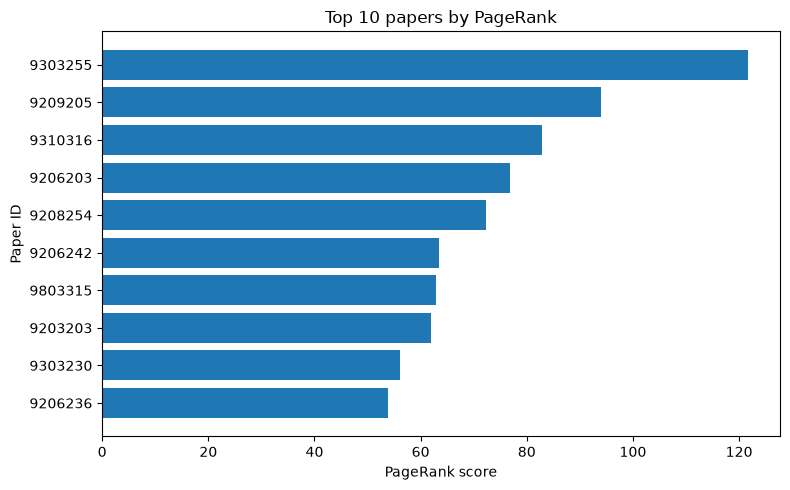

In [26]:
import matplotlib.pyplot as plt

top10_pd = (
    ranked_df.orderBy(F.col("pagerank_score").desc())
    .select("id", "pagerank_score")
    .limit(10)
    .toPandas()
)

plt.figure(figsize=(8, 5))
plt.barh(top10_pd["id"].astype(str), top10_pd["pagerank_score"])
plt.xlabel("PageRank score")
plt.ylabel("Paper ID")
plt.title("Top 10 papers by PageRank")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Export to Neo4j

In [27]:
from src.utils.neo4j_schema import ensure_paper_id_constraint

ensure_paper_id_constraint()

Ensured uniqueness constraint on :Paper(id)


In [28]:
from src.export.neo4j_exporter import Neo4jExporter

Neo4jExporter.write_nodes(ranked_df)

26/10/04 18:47:00 WARN Neo4jOptions: 
Option `schema.optimization.type` is deprecated and will be removed in future implementations,
please move to one of the following depending on your use case:
- `schema.optimization.node.keys`
- `schema.optimization.relationship.keys`

26/10/04 18:47:00 WARN Neo4jOptions: 
Option `schema.optimization.type` is deprecated and will be removed in future implementations,
please move to one of the following depending on your use case:
- `schema.optimization.node.keys`
- `schema.optimization.relationship.keys`

                                                                                

[Neo4jExporter] Wrote 34546 :Paper nodes to Neo4j


In [29]:
Neo4jExporter.write_relationships(edges)
print("Done — open Neo4j Browser (http://localhost:7474) to explore the graph.")

[Neo4jExporter] Wrote 421534 :CITES relationships to Neo4j
Done — open Neo4j Browser (http://localhost:7474) to explore the graph.


In [19]:
print(spark.sparkContext.uiWebUrl) 

http://192.168.1.8:4040


## Cleanup

In [ ]:
spark.stop()